<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/00_1_RNA_SKLearn_EZ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Redes Neuronales Artificiales con ScikitLearn

por Eduardo Zurek, Ph.D.

Profesor Titular

Departamento de Ingeniería de Sistemas

Universidad del Norte

Barranquilla, Mayo 3 de 2021

#IMPORTANTE: Analizar el efecto de la velocidad - Learning rate usando el ejemplo RNA_BP_Multicapa_EZ.m

[0 1 2 3]


Text(0, 0.5, 'Peso en kilogramos')

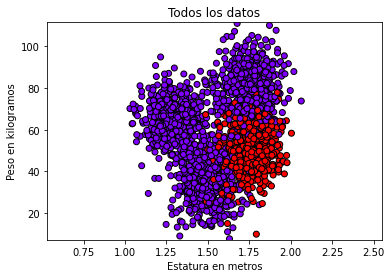

In [ ]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

X, y = make_blobs(n_samples=[500,500,500,500],
                  n_features = 4,
                  centers=[[1.50,35],[1.75,80],[1.30,65],[1.75,50]],
                  cluster_std = [[0.1,10],[0.1,10],[0.1,10],[0.1,10]],
                  random_state=1970)
print(np.unique(y))
y = (y>2.0)+1
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))
cm = plt.cm.rainbow
cm_bright = cm
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

In [ ]:
from sklearn import preprocessing
X_estandarizada = preprocessing.scale(X)
X = X_estandarizada

Text(0, 0.5, 'Peso en kilogramos')

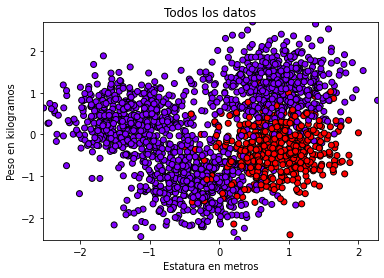

In [ ]:
x_min, x_max = X[:, 0].min() - .01, X[:, 0].max() + .01
y_min, y_max = X[:, 1].min() - .01, X[:, 1].max() + .01
h = 0.02  # step size in the mesh
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                      np.arange(y_min, y_max, h))

# just plot the dataset first
#cm = plt.cm.RdBu
#cm_bright = ListedColormap(['#FF0000', '#0000FF','#0FF000', '#000000'])
ax = plt.figure()
plt.title("Todos los datos")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

In [ ]:
from sklearn.neural_network import MLPClassifier
MLP_EZ = MLPClassifier(hidden_layer_sizes=(5, 2), activation='relu',max_iter=20000)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.33, random_state=1970)

Text(0, 0.5, 'Peso en kilogramos')

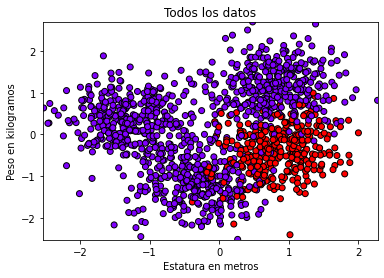

In [ ]:
ax = plt.figure()
plt.title("Datos de entrenamiento")
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

Text(0, 0.5, 'Peso en kilogramos')

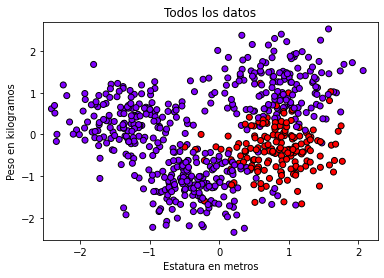

In [ ]:
ax = plt.figure()
plt.title("Datos de prueba")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright,
            edgecolors='k')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel("Estatura en metros")
plt.ylabel("Peso en kilogramos")

In [ ]:
MLP_EZ.fit(X_train, y_train)

MLPClassifier(activation='relu', alpha=0.0001, batch_size='auto', beta_1=0.9,
              beta_2=0.999, early_stopping=False, epsilon=1e-08,
              hidden_layer_sizes=(5, 2), learning_rate='constant',
              learning_rate_init=0.001, max_fun=15000, max_iter=20000,
              momentum=0.9, n_iter_no_change=10, nesterovs_momentum=True,
              power_t=0.5, random_state=None, shuffle=True, solver='adam',
              tol=0.0001, validation_fraction=0.1, verbose=False,
              warm_start=False)

In [ ]:
y_predicho = MLP_EZ.predict(X_test)

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_predicho)

array([[462,  27],
       [ 25, 146]])

In [ ]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test,y_predicho))

0.9212121212121213


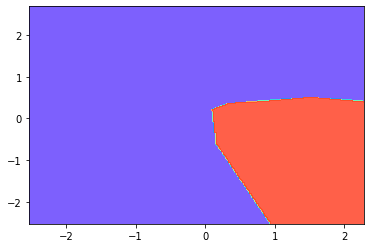

In [ ]:
ZT =clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])
Z = (ZT[:, 0]<ZT[:, 1])
# Put the result into a color plot
Z1 = Z.reshape(xx.shape)
plt.figure()
plt.contourf(xx, yy, Z1, cmap=cm, alpha=.8)